# Settings

In [1]:
#Simulation settings
using_simulation_data = False
parameters_file_path = "/home/matmat/Documents/urban_lab/002_Superresolution/superresolution/data_bf/npy/pig/pig_param.json"
convert_to_iq = False
rf_matrix_path = "./data/npy/rf_data/rf_matrix_summed.npy"

#Real data settings
imported_rf_matrix_delay_unit = "us"
using_matlab_data = True
matlab_rf_data_path = "/home/matmat/Documents/urban_lab/002_Superresolution/raw_data/matthieu/rf0001.mat"
interpolate_data = True

#Batch processing settings
batch_processing = True
batch_size = 10

#Beamforming settings
run_nsi_apodization = False
nsi_dc_offset = 0.1
other_apodization = "rectangle".lower()

#Saving parameters
save_data = True
beamformed_apodized_matrix_name = "001_pig"
folder_name = "pig"
bf_data_path = "./data_bf/npy/"

# Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import json
import timeit
import os
from numba import njit
from scipy.signal import envelope, firwin, hilbert
from scipy.io import loadmat

# Import parameters

In [3]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [4]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [5]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.0075120000000000004 m


In [6]:
if not os.path.exists(f"{bf_data_path}{folder_name}"):
    print(f"Folder {bf_data_path}{folder_name} doesn't exist. Setting up the folder.")
    os.makedirs(f"{bf_data_path}{folder_name}")
    os.makedirs(f"{bf_data_path}{folder_name}/beamformed_final")
    os.makedirs(f"{bf_data_path}{folder_name}/beamformed_apodized")

# Import RF matrix

In [7]:
def load_rf_data(file_path, desired_frames : list, using_simulation_data, using_matlab_data, imported_rf_matrix_delay_unit):
    if using_simulation_data:

        rf_matrix_path = file_path
        rf_matrix_summed = np.load(rf_matrix_path)
        rf_matrix_summed = rf_matrix_summed[:,:,:,desired_frames[0]:desired_frames[1]]
        print("Imported RF matrix with shape: ", rf_matrix_summed.shape)

    else:
        if using_matlab_data:
            rf_matrix_summed = loadmat(matlab_rf_data_path)
            rf_matrix_summed = list(rf_matrix_summed.values())[-1]
            rf_matrix_summed = rf_matrix_summed[:,:,:,desired_frames[0]:desired_frames[1]]
            rf_matrix_summed = np.float64(rf_matrix_summed)
            print("Imported RF matrix with shape: ", rf_matrix_summed.shape)

        match imported_rf_matrix_delay_unit.lower():
            case "s":
                rf_matrix_summed = rf_matrix_summed
                print("Delay unit is in seconds")
            case "ms":
                rf_matrix_summed = rf_matrix_summed * 1e-3
                print("Delay unit is in milliseconds, converting to seconds")
            case "us":
                rf_matrix_summed = rf_matrix_summed * 1e-6
                print("Delay unit is in microseconds, converting to seconds")
            case "ns":
                rf_matrix_summed = rf_matrix_summed * 1e-9
                print("Delay unit is in nanoseconds, converting to seconds")
            case _:
                rf_matrix_summed = rf_matrix_summed
                print("Unknown delay unit, please check the imported delay unit")

    return rf_matrix_summed

# Interpolation

In [8]:
@njit()
def zero_stuffing(rf_matrices_summed, interpolation_factor, upsampled_samples):
    interpolation_factor = interpolation_factor - 1
    
    new_matrices_summed = np.zeros((upsampled_samples, rf_matrices_summed.shape[1], rf_matrices_summed.shape[2]))
    
    for i in range(rf_matrices_summed.shape[2]): #for each angle
        for j in range(rf_matrices_summed.shape[1]): #for each transducer
            for k in range(rf_matrices_summed.shape[0]): #for each sample
                idx_new = k + (interpolation_factor * k)
                new_matrices_summed[idx_new, j, i] = rf_matrices_summed[k, j, i]

    return new_matrices_summed

In [9]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed, frequency, sampling_frequency):
    filtered_rf_matrices_summed = np.zeros((zero_stuffed_rf_matrices_summed.shape[0], zero_stuffed_rf_matrices_summed.shape[1], zero_stuffed_rf_matrices_summed.shape[2]))

    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    cutoff_freq = 0.50 * frequency #use Nyquist frequency as cutoff frequency
    
    filtering_function = firwin(new_samples, cutoff_freq, fs=sampling_frequency)

    for i in range(0, zero_stuffed_rf_matrices_summed.shape[2]): #for each angle
        for j in range(0, zero_stuffed_rf_matrices_summed.shape[1]): #for each transducer
            filtered_rf_matrices_summed[:,j,i] = np.convolve(zero_stuffed_rf_matrices_summed[:,j,i], filtering_function, mode='same')

    return filtered_rf_matrices_summed

# Effective aperture

In [10]:
@njit()
def find_object_effective_aperture(current_position, current_depth, aperture, array_length, pitch):
    effective_array_length =  current_depth / aperture
    first_transducer = -1
    transducers_in_effective_array = 0
    
    for j in range(0, array_length):
        if j*pitch >= current_position - effective_array_length / 2 and j*pitch <= current_position + effective_array_length / 2:
            if first_transducer == -1:
                first_transducer = j
            transducers_in_effective_array += 1
    
    return effective_array_length, transducers_in_effective_array, first_transducer   

# Apodization

## Apodization functions

In [11]:
@njit()
def generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False):
    result = np.zeros(array_length) + offset
    
    for transducer_idx in range(array_length):
        if transducer_idx - first_transducer >= 0:  # making sure we are in the effective array range
            transducer_relative_idx = transducer_idx - first_transducer
            if 0 <= transducer_relative_idx < transducers_in_effective_array / 2:
                result[transducer_idx] = (-1 if mirror else 1) + offset
            elif transducers_in_effective_array / 2 <= transducer_relative_idx < transducers_in_effective_array:
                result[transducer_idx] = (1 if mirror else -1) + offset

    return result

@njit()
def generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0):
    result = np.zeros(array_length) + offset
    
    half_array = effective_array_length / 2
    amount_trimmed = (1 - amount_kept) * half_array
    
    for transducer_idx in range(array_length):
        position = transducer_idx * pitch
        lower_bound = current_position - half_array + amount_trimmed
        upper_bound = current_position + half_array - amount_trimmed
        
        if lower_bound <= position <= upper_bound:
            result[transducer_idx] = 1 + offset
        else:
            result[transducer_idx] = 0 + offset
    
    return result

In [12]:
@njit()
def apodization_wrapper(apodization_function, first_transducer, transducers_in_effective_array, effective_array_length, array_length, current_position, amount_kept, pitch, offset=0, mirror=False):
    
    match apodization_function:
        case "zm":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False)
        case "dc1":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=False)
        case "dc2":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=True)
        case "rectangle":
            return generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0)
        case _:
            return np.ones(array_length)

Effective array length:  0.005000197722239797 first_transducer:  23 transducers_in_effective_array:  55


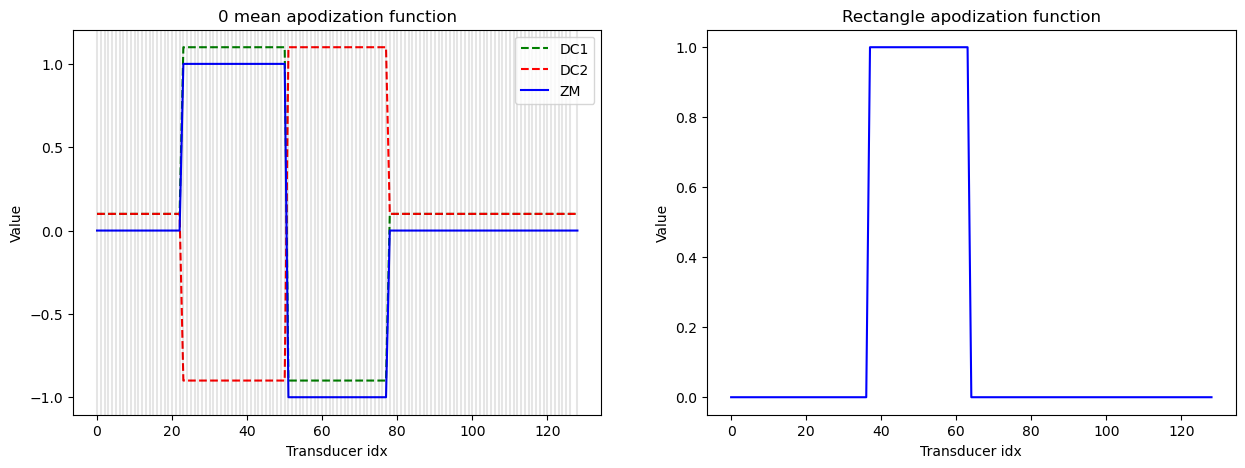

In [13]:
effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(200*2.25e-5, 1331*0.0095/3161, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])
print("Effective array length: ", effective_array_length, "first_transducer: ", first_transducer, "transducers_in_effective_array: ", transducers_in_effective_array)

apodization_zm = apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_dc1 = apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_dc2 = apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_rectangle = apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])

fig, ax = plt.subplots(1,2, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')
for x in pos:
    ax[0].axvline(x=x, color='black', ls='-', alpha=0.1)
ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')
plt.show()

# Envelopes

In [14]:
def get_envelope(bf_matrix, frames):
    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution, frames))
    for i in range(0, frames):
        for j in range(0, lateral_resolution):
            env[:,j,i] = envelope(bf_matrix[:,j,i], residual=None)
    return env

# Beamforming

In [15]:
@njit()
def get_samples_depth_lateral_resolution(samples, sampling_rate, c, dx, dz, pitch, array_length):
    max_acquisition_depth = c * (1 / sampling_rate * samples) / 2
    samples_for_acquisition_depth = int(max_acquisition_depth / dz)
    samples_for_array_length = int(array_length * pitch / dx)

    return max_acquisition_depth, samples_for_acquisition_depth, samples_for_array_length

In [16]:
def save_beamformed_data(bf_matrix, filename, destination=f"{bf_data_path}/{folder_name}/beamformed_final/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data of shape {bf_matrix.shape} saved at: {destination}{filename}.npy")

In [17]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, nx, nz, dx, dz, x0, z0, delay0, pitch, c, array_length, samples, sampling_rate, aperture, apodization_function, using_real_data, frames, debug, angles = [0]):

    max_acquisition_depth, samples_for_acquisition_depth, samples_for_array_length = get_samples_depth_lateral_resolution(samples, sampling_rate, c, dx, dz, pitch, array_length)
    fixed_delay = delay0 * 1/sampling_rate

    bf_matrix = np.zeros((samples_for_acquisition_depth, samples_for_array_length, len(angles), frames), dtype=np.float64)

    if nx is None:
        nx = samples_for_array_length
    if nz is None:
        nz = samples_for_acquisition_depth

    if debug:
        print("\n" + "="*60)
        print(f"✓ BEAMFORMING CONFIGURATION:")
        print(f"  • Resolution: {nx} x {nz}")
        print(f"  • Acquisition depth:",max_acquisition_depth,"m",f"({samples_for_acquisition_depth} samples)")
        print(f"  • Fixed delay:",fixed_delay,"s",f"({delay0} samples)")
        print(f"  • Array length:",array_length * pitch,"m",f"({samples_for_array_length} samples)")
        print(f"  • Apodization: {apodization_function}")
        print(f"  • Processing {len(angles)} angle(s)")
        print("-"*60)

    for h in range(0, frames): #for each frame
        if debug:
            print(f"  ↳ Processing frame",h+1,f"[{h+1}/{frames}]")
    
        for i in range(0, len(angles)): #for each angle
            if debug:
                print(f"    ↳ Processing angle",angles[i],"°",f"[{i+1}/{len(angles)}]")

            cos_angle = np.cos(angles[i] * np.pi/180)
            sin_angle = np.sin(angles[i] * np.pi/180)

            additional_delay = 0
            
            if angles[i] < 0 and using_real_data:
                additional_delay = (array_length * pitch) * sin_angle / c
            
            for j in range(0, samples_for_array_length): #for each lateral res sample

                if j < x0 or j > x0 + nx:
                    continue

                for k in range(0, samples_for_acquisition_depth): #for vertical res sample

                    if k < z0 or k > z0 + nz:
                        continue

                    depth = dz*k
                    position = dx*j

                    effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(position, depth, aperture, array_length, pitch)

                    apodization = apodization_wrapper(
                        apodization_function, 
                        first_transducer, 
                        transducers_in_effective_array, 
                        effective_array_length, 
                        array_length, 
                        position, 
                        0.5, 
                        pitch
                    )

                    for l in range(0, array_length): #for each transducer
                        delay = ((depth * cos_angle + position * sin_angle) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c) - additional_delay - fixed_delay #delay in s
                        delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)
                        if delay_idx < samples:
                            bf_matrix[k,j,i,h] += rf_summed_matrices[delay_idx, l, i, h] * apodization[l] #we use previously computed values for better perf
    if debug:
        print("-"*60)
        print(f"✓ BEAMFORMING COMPLETE")
        print(f"  • Output shape: ", bf_matrix.shape)
        print("="*60 + "\n")
    return bf_matrix

# Run beamforming

In [18]:
#load right parameters for batch processing 
if params["image"]["nframes"] % batch_size == 0:
    frame_iterations = params["image"]["nframes"] // batch_size
else:
    frame_iterations = params["image"]["nframes"] // batch_size + 1

print(f"Frame iterations: {frame_iterations}")
if batch_processing:
    print(f"Batch processing with {batch_size} frames")

if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]

apo_funcs = ["zm", "dc1", "dc2"] if run_nsi_apodization else [other_apodization]

max_acquisition_depth, samples_for_acquisition_depth, samples_for_array_length = get_samples_depth_lateral_resolution(samples, sampling_rate, C, params["image"]["dx"], params["image"]["dz"], params["array"]["pitch"], params["array"]["length"])

#create numpy matrices for batch processing

for apo_func in apo_funcs:
    apodized_bf_image = np.zeros((samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]), dtype=np.float64)
    save_beamformed_data(apodized_bf_image, f"{beamformed_apodized_matrix_name}_{apo_func}", destination=f"{bf_data_path}{folder_name}/beamformed_apodized/")

Frame iterations: 25
Batch processing with 10 frames
Beamformed data of shape (333, 512, 250) saved at: ./data_bf/npy/pig/beamformed_apodized/001_pig_rectangle.npy


In [19]:
start = timeit.default_timer() 

for i in range(0, frame_iterations * batch_size, batch_size):
    #might neeed to handle exception for uneven number of frames to process 
    
    
    print("\n" + "="*60)
    print(f"Processing batch", int(i / batch_size) + 1,f"[{int(i / batch_size) + 1}/{frame_iterations}]")

    #Load rf data

    rf_matrix_summed = load_rf_data(rf_matrix_path, [i,i+batch_size], using_simulation_data, using_matlab_data, imported_rf_matrix_delay_unit)

    print(f"  • Processing from frame {i} to frame {i+rf_matrix_summed.shape[3]}")
    print(f"  • Processing {rf_matrix_summed.shape[3]} frame(s)")

    #Interpolate data

    if interpolate_data:

        print("  • Interpolating data")

        rf_matrix_summed_tmp = np.zeros((params["rf"]["upsampled_samples"], rf_matrix_summed.shape[1], rf_matrix_summed.shape[2], rf_matrix_summed.shape[3]))

        for j in range(rf_matrix_summed_tmp.shape[3]):
            temp_zero_stuffed = zero_stuffing(rf_matrix_summed[:,:,:,j], params["rf"]["interpolation_factor"], params["rf"]["upsampled_samples"])
            rf_matrix_summed_tmp[:,:,:,j] = get_filtered_matrices(temp_zero_stuffed, params["rf"]["frequency"], params["rf"]["sampling_rate"])
                
        rf_matrix_summed = rf_matrix_summed_tmp
        del temp_zero_stuffed
        del rf_matrix_summed_tmp
        # plt.imshow(np.abs(rf_matrix_summed[:,:,0,0]), aspect='auto', cmap='viridis')
        print("   ↳ Upsampled RF matrix with shape: ", rf_matrix_summed.shape)
        
    #Beamforming

    bf_matrices = []

    print("\nRunning NSI apodizations" if run_nsi_apodization else f"Running {other_apodization} apodization")

    for apo_func in apo_funcs:
        bf_apodized_matrix = beamforming_opt(
            rf_matrix_summed, 
            params["image"]["nx"], 
            params["image"]["nz"],
            params["image"]["dx"],
            params["image"]["dz"],
            params["image"]["x0"],
            params["image"]["z0"],
            params["rf"]["delay0"],
            params["array"]["pitch"], 
            C, 
            params["array"]["length"], 
            samples,
            sampling_rate, 
            params["array"]["aperture"],
            apo_func,
            not using_simulation_data,
            rf_matrix_summed.shape[3],#batch_size,
            False,
            angles= params["rf"]["angles"]
        )
        
        bf_matrices.append(bf_apodized_matrix)

    #Summing angles

    bf_apodized_matrices_summed = [np.sum(bf_apodized_matrices_loaded, axis=2) for bf_apodized_matrices_loaded in bf_matrices]

    #Applying envelope

    if run_nsi_apodization:
        
        bf_apodized_matrices_summed[0] = get_envelope(bf_apodized_matrices_summed[0], frames=rf_matrix_summed.shape[3])
        bf_apodized_matrices_summed[1] = get_envelope(bf_apodized_matrices_summed[1], frames=rf_matrix_summed.shape[3])
        bf_apodized_matrices_summed[2] = get_envelope(bf_apodized_matrices_summed[2], frames=rf_matrix_summed.shape[3])

        print("bf_matrix_zm shape: ", bf_apodized_matrices_summed[0].shape)
        print("bf_matrix_dc1 shape: ", bf_apodized_matrices_summed[1].shape)
        print("bf_matrix_dc2 shape: ", bf_apodized_matrices_summed[2].shape)

    else:
        print("bf_matrix_apo shape: ", bf_apodized_matrices_summed[0].shape)
    
    #Append to saved matrix

    for j, apo_func in enumerate(apo_funcs):
        memmap_bf_matrix = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_{apo_func}.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
        memmap_bf_matrix[:,:,i:i+rf_matrix_summed.shape[3]] = bf_apodized_matrices_summed[j]

    del bf_apodized_matrices_summed
    del bf_matrices
    del rf_matrix_summed
    del bf_apodized_matrix
    del memmap_bf_matrix

    print("="*60 + "\n")
        
                    
end = timeit.default_timer()
print(f"Beamforming took: {end - start} seconds")   


Processing batch 1 [1/25]
Imported RF matrix with shape:  (626, 128, 31, 10)
Delay unit is in microseconds, converting to seconds
  • Processing from frame 0 to frame 10
  • Processing 10 frame(s)
  • Interpolating data
   ↳ Upsampled RF matrix with shape:  (2501, 128, 31, 10)
Running rectangle apodization
bf_matrix_apo shape:  (333, 512, 10)


Processing batch 2 [2/25]
Imported RF matrix with shape:  (626, 128, 31, 10)
Delay unit is in microseconds, converting to seconds
  • Processing from frame 10 to frame 20
  • Processing 10 frame(s)
  • Interpolating data
   ↳ Upsampled RF matrix with shape:  (2501, 128, 31, 10)
Running rectangle apodization
bf_matrix_apo shape:  (333, 512, 10)


Processing batch 3 [3/25]
Imported RF matrix with shape:  (626, 128, 31, 10)
Delay unit is in microseconds, converting to seconds
  • Processing from frame 20 to frame 30
  • Processing 10 frame(s)
  • Interpolating data
   ↳ Upsampled RF matrix with shape:  (2501, 128, 31, 10)
Running rectangle apodiza

# Apply NSI 

In [20]:
if run_nsi_apodization:
    env_nsi = np.zeros((samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
    save_beamformed_data(env_nsi, f"{beamformed_apodized_matrix_name}_env_nsi", destination=f"{bf_data_path}{folder_name}/beamformed_apodized/")

    memmap_bf_matrix_zm = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_zm.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
    memmap_bf_matrix_dc1 = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_dc1.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
    memmap_bf_matrix_dc2 = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_dc2.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))

    for i in range(0, params["image"]["nframes"]):

        memmap_env_nsi = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_env_nsi.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
        memmap_env_nsi[:,:,i] = (memmap_bf_matrix_dc1[:,:,i] + memmap_bf_matrix_dc2[:,:,i]) / 2 - memmap_bf_matrix_zm[:,:,i]
    
    del memmap_env_nsi
    del memmap_bf_matrix_zm
    del memmap_bf_matrix_dc1
    del memmap_bf_matrix_dc2
    del env_nsi

# Sum frames

In [21]:
if run_nsi_apodization:
    final_bf_image = np.zeros((samples_for_acquisition_depth, samples_for_array_length))
    save_beamformed_data(final_bf_image, f"{beamformed_apodized_matrix_name}_env_nsi", destination=f"{bf_data_path}/{folder_name}/beamformed_final/")

    memmap_final_bf_image = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_final/{beamformed_apodized_matrix_name}_env_nsi.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length))

    for i in range(0, params["image"]["nframes"]):

        memmap_env_nsi = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_env_nsi.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
        memmap_final_bf_image += memmap_env_nsi[:,:,i]

    del memmap_env_nsi
    del memmap_final_bf_image
    del final_bf_image

else:
    final_bf_image = np.zeros((samples_for_acquisition_depth, samples_for_array_length))
    save_beamformed_data(final_bf_image, f"{beamformed_apodized_matrix_name}_{other_apodization}", destination=f"{bf_data_path}{folder_name}/beamformed_final/")

    memmap_final_bf_image = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_final/{beamformed_apodized_matrix_name}_{other_apodization}.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length))

    for i in range(0, params["image"]["nframes"]):

        memmap_bf_matrix_apo = np.lib.format.open_memmap(f"{bf_data_path}{folder_name}/beamformed_apodized/{beamformed_apodized_matrix_name}_{other_apodization}.npy", dtype=np.float64, mode='r+', shape=(samples_for_acquisition_depth, samples_for_array_length, params["image"]["nframes"]))
        memmap_final_bf_image += memmap_bf_matrix_apo[:,:,i]

    del memmap_bf_matrix_apo
    del memmap_final_bf_image
    del final_bf_image
    

Beamformed data of shape (333, 512) saved at: ./data_bf/npy/pig/beamformed_final/001_pig_rectangle.npy


## Show beamformed image

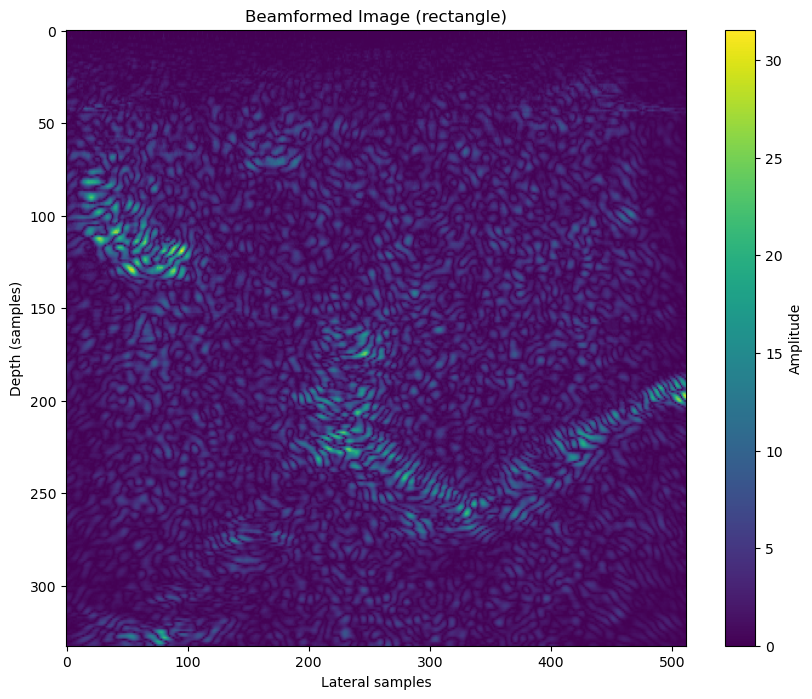

In [22]:
bf_image = np.load(f"{bf_data_path}{folder_name}/beamformed_final/{beamformed_apodized_matrix_name}_env_nsi.npy" if run_nsi_apodization else f"{bf_data_path}{folder_name}/beamformed_final/{beamformed_apodized_matrix_name}_{other_apodization}.npy")

plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_image), cmap='viridis', aspect='auto')
plt.title(f"Beamformed Image ({'env_nsi' if run_nsi_apodization else other_apodization})")
plt.xlabel("Lateral samples")
plt.ylabel("Depth (samples)")

#box around the xo, zo, nx, nz
x0 = params["image"]["x0"]
z0 = params["image"]["z0"]
nx = params["image"]["nx"]
nz = params["image"]["nz"]

if nx is not None and nz is not None:
    plt.plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label='ROI')
    plt.legend()

plt.colorbar(label="Amplitude") 

if save_data:
    plt.savefig(f"./data_bf/images/{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}.png")
plt.show()